# Rossmann Store Sales – Forecasting

**Goal:** Forecast daily sales per store for the last 6 weeks of data and compare
a simple baseline with machine learning models.

In [2]:
from google.colab import drive
drive.mount('/content/drive')

import numpy as np
import pandas as pd

DATA_DIR = '/content/drive/MyDrive/rossmann-sales-analysis/data/'
FIG_DIR = '/content/drive/MyDrive/rossmann-sales-analysis/figures/'

df = pd.read_parquet(DATA_DIR + 'train_clean.parquet')

# Time-based split: the last 6 weeks (42 days) are the test set
split_date = df['Date'].max() - pd.Timedelta(days=41)
train = df[df['Date'] < split_date]
test = df[df['Date'] >= split_date]

print('Train:', train['Date'].min().date(), 'to', train['Date'].max().date(), '|', len(train), 'rows')
print('Test: ', test['Date'].min().date(), 'to', test['Date'].max().date(), '|', len(test), 'rows')

Mounted at /content/drive
Train: 2013-01-01 to 2015-06-19 | 804056 rows
Test:  2015-06-20 to 2015-07-31 | 40282 rows


In [3]:
def rmspe(y_true, y_pred):
    """Root Mean Squared Percentage Error (the official Kaggle metric for this data)."""
    return np.sqrt(np.mean(((y_true - y_pred) / y_true) ** 2)) * 100

def mae(y_true, y_pred):
    return np.mean(np.abs(y_true - y_pred))

In [4]:
keys = ['Store', 'DayOfWeek', 'Promo']
baseline = train.groupby(keys)['Sales'].mean().rename('pred_baseline').reset_index()

results = test.merge(baseline, on=keys, how='left')

# Fallback for rare combinations not seen in training: store average
store_mean = train.groupby('Store')['Sales'].mean()
results['pred_baseline'] = results['pred_baseline'].fillna(results['Store'].map(store_mean))

print('Missing predictions:', results['pred_baseline'].isna().sum())
print(f"Baseline – RMSPE: {rmspe(results['Sales'], results['pred_baseline']):.1f}%  "
      f"| MAE: {mae(results['Sales'], results['pred_baseline']):.0f}")

Missing predictions: 0
Baseline – RMSPE: 14.7%  | MAE: 744


In [5]:
import lightgbm as lgb

def add_features(data):
    d = data.copy()
    d['Year'] = d['Date'].dt.year
    d['Month'] = d['Date'].dt.month
    d['Day'] = d['Date'].dt.day
    d['WeekOfYear'] = d['Date'].dt.isocalendar().week.astype(int)

    # Months since the nearest competitor opened (NaN if unknown)
    d['CompetitionOpenMonths'] = (12 * (d['Year'] - d['CompetitionOpenSinceYear'])
                                  + (d['Month'] - d['CompetitionOpenSinceMonth']))

    # Is Promo2 running in this month? (PromoInterval uses 'Sept', pandas uses 'Sep')
    month_abbr = d['Date'].dt.strftime('%b')
    intervals = d['PromoInterval'].fillna('').str.replace('Sept', 'Sep')
    d['IsPromo2Month'] = [int(m in pi.split(',')) for m, pi in zip(month_abbr, intervals)]

    for col in ['Store', 'StoreType', 'Assortment', 'StateHoliday']:
        d[col] = d[col].astype('category')
    return d

data = add_features(df)

# Only features that are known in advance. 'Customers' is excluded (data leakage).
features = ['Store', 'DayOfWeek', 'Promo', 'StateHoliday', 'SchoolHoliday',
            'StoreType', 'Assortment', 'CompetitionDistance', 'CompetitionOpenMonths',
            'Promo2', 'IsPromo2Month', 'Year', 'Month', 'Day', 'WeekOfYear']

In [6]:
valid_start = split_date - pd.Timedelta(days=42)

tr = data[data['Date'] < valid_start]
va = data[(data['Date'] >= valid_start) & (data['Date'] < split_date)]
te = data[data['Date'] >= split_date]

print('Train:', len(tr), '| Validation:', len(va), '| Test:', len(te))

Train: 766584 | Validation: 37472 | Test: 40282


In [7]:
params = {
    'objective': 'regression',
    'learning_rate': 0.1,
    'num_leaves': 63,
    'min_data_in_leaf': 100,
    'feature_fraction': 0.8,
    'bagging_fraction': 0.8,
    'bagging_freq': 1,
    'seed': 42,
    'verbose': -1
}

dtrain = lgb.Dataset(tr[features], label=np.log1p(tr['Sales']))
dvalid = lgb.Dataset(va[features], label=np.log1p(va['Sales']), reference=dtrain)

model = lgb.train(params, dtrain, num_boost_round=2000, valid_sets=[dvalid],
                  callbacks=[lgb.early_stopping(100), lgb.log_evaluation(200)])
print('Best number of trees:', model.best_iteration)

Training until validation scores don't improve for 100 rounds
[200]	valid_0's l2: 0.0166205
Early stopping, best iteration is:
[241]	valid_0's l2: 0.0165646
Best number of trees: 241


In [8]:
full = data[data['Date'] < split_date]
dfull = lgb.Dataset(full[features], label=np.log1p(full['Sales']))
final_model = lgb.train(params, dfull, num_boost_round=model.best_iteration)

# Check that rows are in the same order as the baseline results
assert (results['Store'].values == te['Store'].astype(int).values).all()
assert (results['Date'].values == te['Date'].values).all()

results['pred_lgbm'] = np.expm1(final_model.predict(te[features]))

for name, col in [('Baseline', 'pred_baseline'), ('LightGBM', 'pred_lgbm')]:
    print(f"{name:9s} – RMSPE: {rmspe(results['Sales'], results[col]):.1f}%  "
          f"| MAE: {mae(results['Sales'], results[col]):.0f}")

Baseline  – RMSPE: 14.7%  | MAE: 744
LightGBM  – RMSPE: 13.1%  | MAE: 622


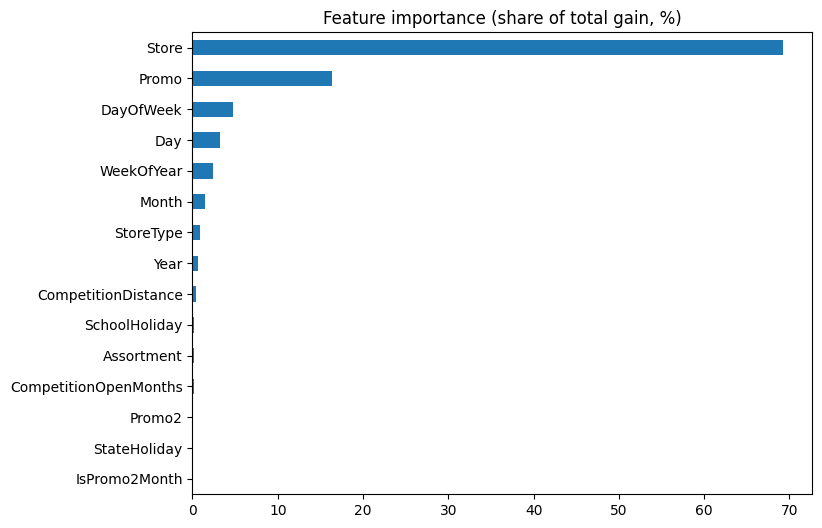

In [9]:
import matplotlib.pyplot as plt

imp = pd.Series(final_model.feature_importance(importance_type='gain'), index=features).sort_values()
(imp / imp.sum() * 100).plot(kind='barh', figsize=(8, 6),
                             title='Feature importance (share of total gain, %)')
plt.savefig(FIG_DIR + 'feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()

In [10]:
results['ape_baseline'] = np.abs(results['Sales'] - results['pred_baseline']) / results['Sales'] * 100
results['ape_lgbm'] = np.abs(results['Sales'] - results['pred_lgbm']) / results['Sales'] * 100

print('Mean absolute percentage error by store type:')
display(results.groupby('StoreType')[['ape_baseline', 'ape_lgbm']].mean().round(1))

print('By promo:')
display(results.groupby('Promo')[['ape_baseline', 'ape_lgbm']].mean().round(1))

Mean absolute percentage error by store type:


,ape_baseline,ape_lgbm
StoreType,,
a,11.0,9.4
b,11.8,8.5
c,11.2,9.5
d,10.2,9.2


By promo:


,ape_baseline,ape_lgbm
Promo,,
0,10.6,9.6
1,11.1,9.0


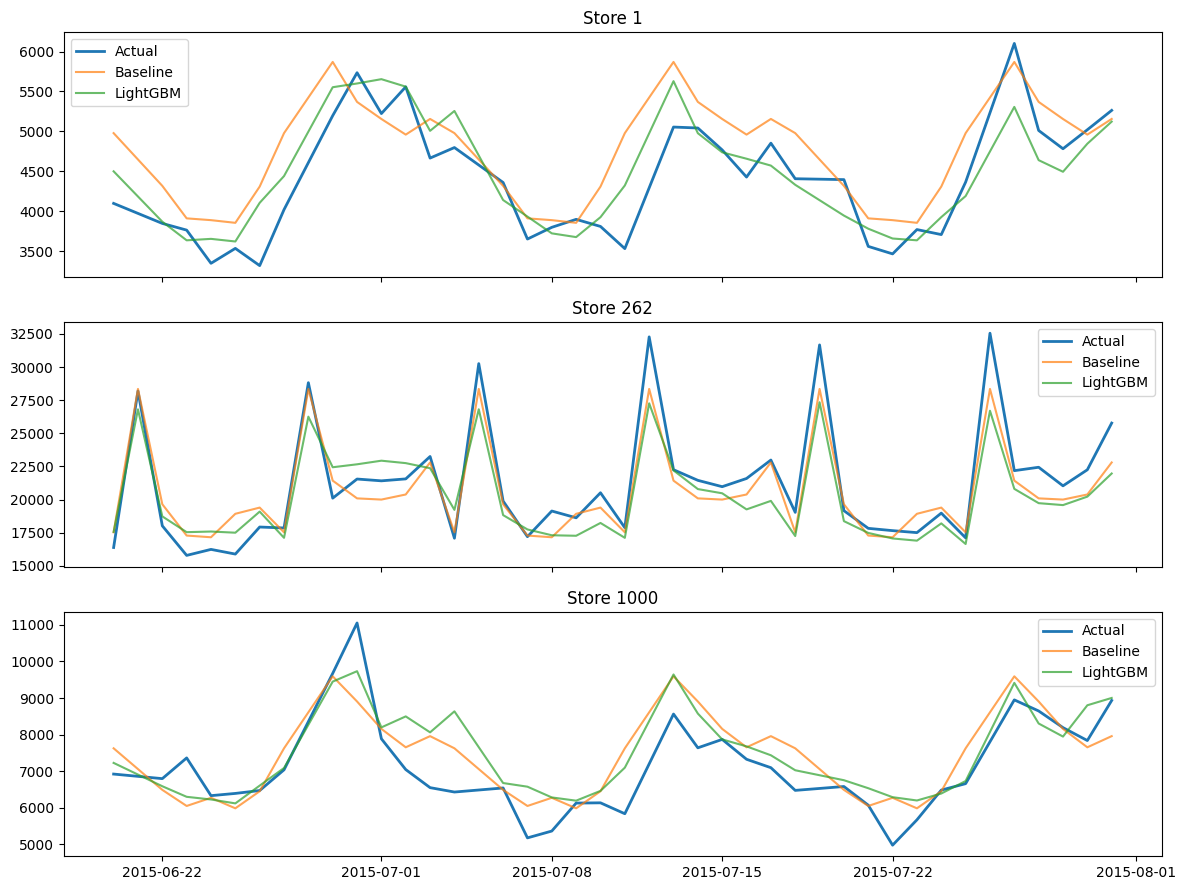

In [11]:
fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
for ax, s in zip(axes, [1, 262, 1000]):
    r = results[results['Store'] == s].sort_values('Date')
    ax.plot(r['Date'], r['Sales'], label='Actual', linewidth=2)
    ax.plot(r['Date'], r['pred_baseline'], label='Baseline', alpha=0.7)
    ax.plot(r['Date'], r['pred_lgbm'], label='LightGBM', alpha=0.7)
    ax.set_title(f'Store {s}')
    ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR + 'forecast_examples.png', dpi=150, bbox_inches='tight')
plt.show()

## Results

| Model | RMSPE | MAE |
|---|---|---|
| Baseline (store × weekday × promo average) | 14.7% | 744 |
| LightGBM | 13.1% | 622 |

LightGBM improves on the baseline (RMSPE −1.6 points, MAE −16%), with the largest gains for
type-b stores and promo days. However, the simple baseline already captures most of the
predictable variation: Store, Promo and DayOfWeek account for about 90% of the model's
feature importance, which is consistent with the EDA and the promotion analysis.

Store attributes (type, assortment, competition) have low importance because the Store
feature already contains this information. Feature importance shows what helps prediction,
not causal effects.

## Limitations and next steps

- The models use no information about recent sales levels. They react slowly when a store's
  level changes (e.g. store 262 at the end of July). Lag and rolling-average features would
  be the next step.
- Very high peaks (e.g. Sundays in type-b stores) are underestimated.
- Hyperparameters were not tuned systematically; the validation set was used only for
  early stopping.